In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
URL = "https://itv-contentbucket.s3.ap-south-1.amazonaws.com/Exams/ML/Linear+Regression/mediclaim.csv"
df = pd.read_csv(URL)          # or pd.read_csv("mediclaim.csv") if downloaded
print(df.shape); display(df.head()) if "display" in globals() else print(df.head())
print(df.info()); print(df.describe())

(1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1
   age  sex     bmi  children  smoker      charges  region_northwest  \
0   19    0  27.900         0       1  16884.92400                 0   
1   18    1  33.770         1       0   1725.55230                 0   
2   28    1  33.000         3       0   4449.46200                 0   
3   33    1  22.705         0       0  21984.47061                 1   
4   32    1  28.880         0       0   3866.85520                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


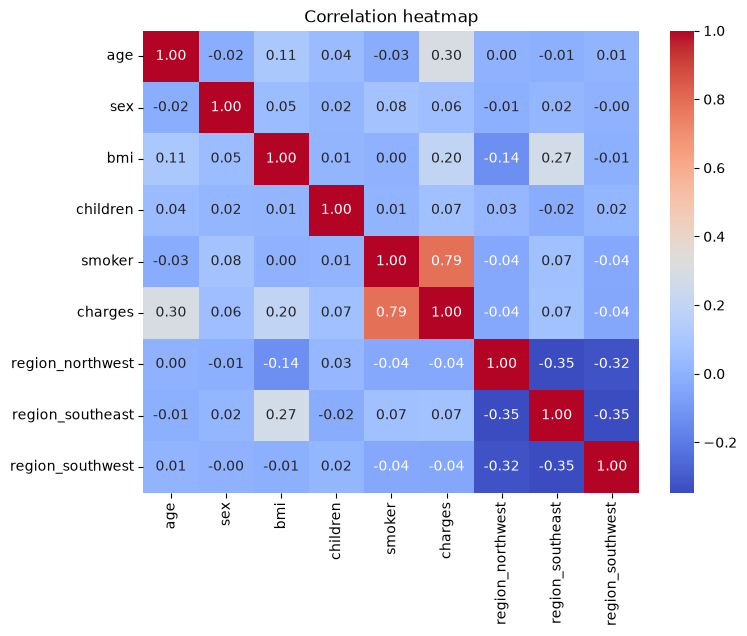

In [3]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Encode categorical variables
df["sex"] = df["sex"].map({"male": 1, "female": 0})
df["smoker"] = df["smoker"].map({"yes": 1, "no": 0})
df = pd.get_dummies(df, columns=["region"], drop_first=True, dtype=int)
print(df.head())

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()


In [4]:
X = df.drop("charges", axis=1)
y = df["charges"]
print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features (needed so the Ridge/Lasso penalty treats all features fairly)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


(1337, 8) (1337,)


In [5]:
def evaluate(name, model, Xtr, Xte):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    n, k = Xte.shape[0], Xte.shape[1]
    r2 = r2_score(y_test, p_te)
    return {"Model": name,
            "Train R2": r2_score(y_train, p_tr),
            "Test R2": r2,
            "Adj R2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
            "MAE": mean_absolute_error(y_test, p_te),
            "MSE": mean_squared_error(y_test, p_te),
            "RMSE": np.sqrt(mean_squared_error(y_test, p_te))}

# %% 3. LINEAR REGRESSION
lr = LinearRegression().fit(X_train_s, y_train)
print("Intercept:", lr.intercept_)
print(pd.Series(lr.coef_, index=X.columns).sort_values())

Intercept: 13030.203369289053
region_southeast    -371.780810
region_southwest    -284.610396
region_northwest    -168.944439
sex                  -50.749675
children             636.501185
bmi                 1927.828251
age                 3472.975553
smoker              9234.342487
dtype: float64


Model       Linear Regression
Train R2             0.729906
Test R2              0.806929
Adj R2               0.800965
MAE               4177.045561
MSE           35478020.675236
RMSE              5956.342894
dtype: object


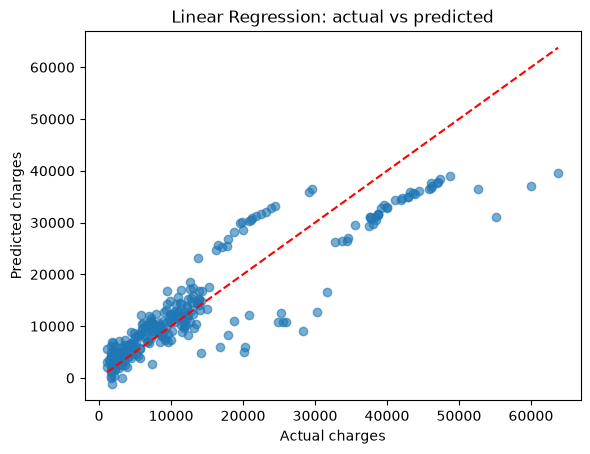

In [6]:
res_lr = evaluate("Linear Regression", lr, X_train_s, X_test_s)
print(pd.Series(res_lr))

plt.scatter(y_test, lr.predict(X_test_s), alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual charges"); plt.ylabel("Predicted charges"); plt.title("Linear Regression: actual vs predicted"); plt.show()


Best Ridge alpha: 10.985411419875572 | Best Lasso alpha: 44.98432668969444
                   Linear    Ridge    Lasso
age               3472.98  3437.27  3439.66
sex                -50.75   -42.17    -0.00
bmi               1927.83  1905.36  1856.91
children           636.50   634.24   595.50
smoker            9234.34  9136.85  9183.51
region_northwest  -168.94  -165.51   -27.25
region_southeast  -371.78  -351.58  -204.76
region_southwest  -284.61  -276.81  -136.27


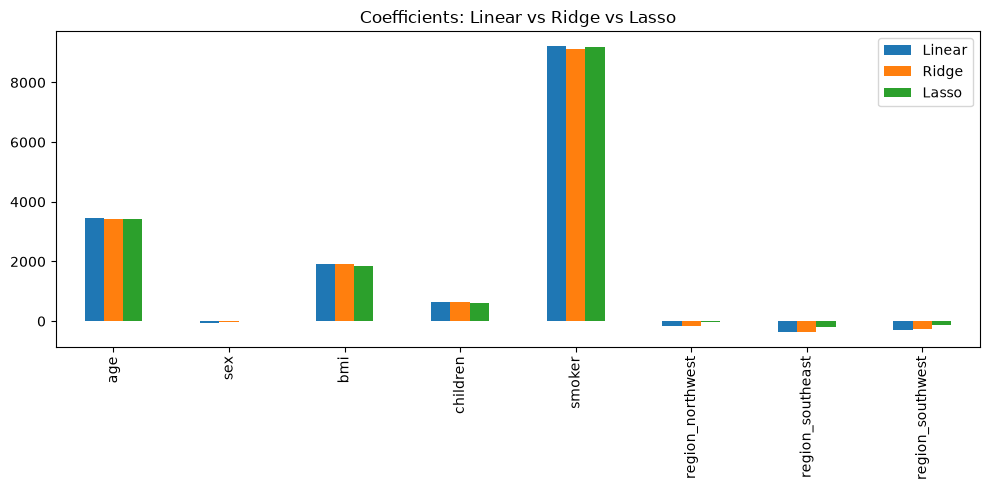

In [7]:
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_s, y_train)
lasso_cv = LassoCV(alphas=np.logspace(-3, 3, 50), cv=5, max_iter=50000).fit(X_train_s, y_train)
print("Best Ridge alpha:", ridge_cv.alpha_, "| Best Lasso alpha:", lasso_cv.alpha_)

ridge = Ridge(alpha=ridge_cv.alpha_).fit(X_train_s, y_train)
lasso = Lasso(alpha=lasso_cv.alpha_, max_iter=50000).fit(X_train_s, y_train)

coefs = pd.DataFrame({"Linear": lr.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=X.columns)
print(coefs.round(2))
coefs.plot.bar(figsize=(10, 5)); plt.title("Coefficients: Linear vs Ridge vs Lasso"); plt.tight_layout(); plt.show()


                   Train R2  Test R2  Adj R2        MAE           MSE  \
Model                                                                   
Linear Regression    0.7299   0.8069  0.8010  4177.0456  3.547802e+07   
Ridge                0.7298   0.8048  0.7988  4205.0770  3.586429e+07   
Lasso                0.7297   0.8050  0.7989  4185.3010  3.584125e+07   

                        RMSE  
Model                         
Linear Regression  5956.3429  
Ridge              5988.6802  
Lasso              5986.7565  


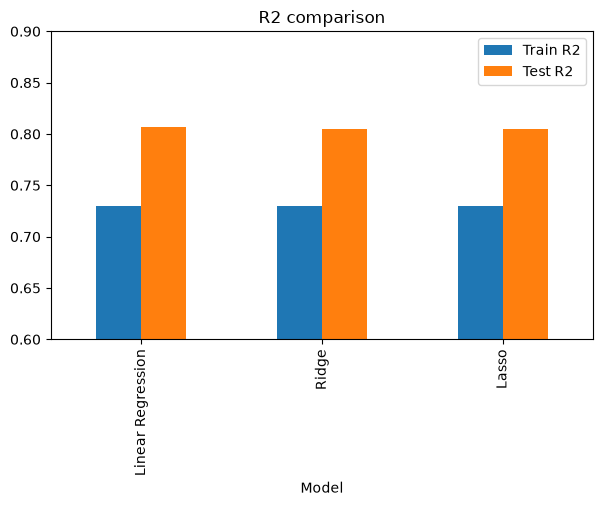

In [8]:
comparison = pd.DataFrame([res_lr,
                           evaluate("Ridge", ridge, X_train_s, X_test_s),
                           evaluate("Lasso", lasso, X_train_s, X_test_s)]).set_index("Model")
print(comparison.round(4))
comparison[["Train R2", "Test R2"]].plot.bar(figsize=(7, 4), ylim=(0.6, 0.9)); plt.title("R2 comparison"); plt.show()
